# Análisis exploratorio de incidencia delictiva en México

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from IPython.display import display, Markdown
%matplotlib inline


In [2]:
# Dataset limpio generado por el cuaderno 1: datos estatales por tipo de delito.
df = pd.read_csv('data/delitos.csv', parse_dates=['fecha'])
assert not df.isna().any().any()
assert not df.duplicated(['fecha', 'clave_ent', 'tipo_de_delito']).any()

# Recuperamos subtipo y modalidad para las preguntas que necesitan más detalle.
crudos = pd.read_csv('data/datos_delitos.csv', encoding='ISO-8859-1')
crudos = crudos.rename(columns={
    'Año': 'anio', 'Clave_Ent': 'clave_ent', 'Entidad': 'entidad',
    'Tipo de delito': 'tipo_de_delito', 'Subtipo de delito': 'subtipo_de_delito',
    'Modalidad': 'modalidad'
})
meses = {nombre: i for i, nombre in enumerate([
    'Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
    'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'
], 1)}
detalle = crudos.melt(
    id_vars=['anio', 'clave_ent', 'entidad', 'tipo_de_delito', 'subtipo_de_delito', 'modalidad'],
    value_vars=list(meses), var_name='nombre_mes', value_name='frecuencia'
).dropna(subset=['frecuencia']).copy()
detalle['fecha'] = pd.to_datetime(pd.DataFrame({
    'year': detalle['anio'], 'month': detalle['nombre_mes'].map(meses), 'day': 1
}))
detalle['frecuencia'] = detalle['frecuencia'].astype('int64')
claves = ['anio', 'clave_ent', 'entidad', 'tipo_de_delito', 'fecha']
comprobacion = detalle.groupby(claves)['frecuencia'].sum().sort_index()
exportado = df.set_index(claves)['frecuencia'].sort_index()
pd.testing.assert_series_equal(comprobacion, exportado)
print(f'Datos limpios: {len(df):,} filas; detalle observado: {len(detalle):,} filas.')
print(f'Cobertura: {df.fecha.min():%Y-%m} a {df.fecha.max():%Y-%m}; 32 entidades.')
print('2024 incluye sólo enero-junio. No hay información municipal en estos archivos.')


Datos limpios: 145,920 filas; detalle observado: 357,504 filas.
Cobertura: 2015-01 a 2024-06; 32 entidades.
2024 incluye sólo enero-junio. No hay información municipal en estos archivos.


**Alcance y fuentes de las respuestas.** `delitos.csv` permite estudiar los tipos
de delito, los pasteles y las tasas mensuales. Para distinguir **homicidio doloso**
y **robo de vehículo automotor**, se usa además el subtipo que sigue disponible
en `datos_delitos.csv`. Su agrupación se verifica contra el archivo limpio.
Los registros son estatales y cubren enero de 2015 a junio de 2024; no se
inventan municipios ni meses posteriores. Las cifras delictivas provienen
exclusivamente de los CSV del repositorio; la población se contrasta con INEGI.


#### Ejercicio 1: Elige 3 estados de la república y grafica una serie de tiempo de la frecuencia abosluta de homicidios dolosos de enero 2015 a julio 2019 en estas tres entidades

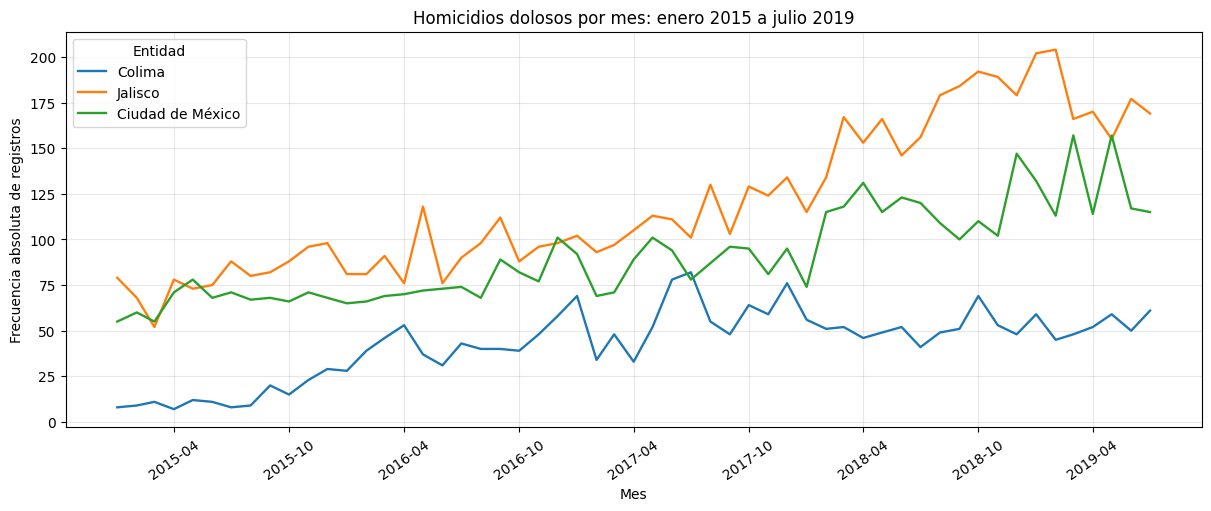

,total_periodo,promedio_mensual,maximo_mensual,mes_del_maximo
entidad,,,,
Colima,2353,42.781818,82,2017-07
Jalisco,6607,120.127273,204,2019-02
Ciudad de México,5021,91.290909,157,2019-03


**Respuesta e interpretación:** se grafican 55 meses completos de homicidios **dolosos**, sumando sus modalidades. De las tres entidades elegidas, **Jalisco** acumula el mayor número en este intervalo (6,607). Son frecuencias absolutas; este gráfico no compara el riesgo por habitante.

In [3]:
estados_elegidos = ['Colima', 'Jalisco', 'Ciudad de México']
dolosos = detalle.loc[detalle['subtipo_de_delito'].eq('Homicidio doloso')].copy()
periodo = dolosos['fecha'].between('2015-01-01', '2019-07-01')
serie = (
    dolosos.loc[periodo & dolosos['entidad'].isin(estados_elegidos)]
    .groupby(['fecha', 'entidad'])['frecuencia'].sum().unstack('entidad')
    .reindex(columns=estados_elegidos).sort_index()
)
assert serie.shape == (55, 3) and serie.notna().all().all()
fig, ax = plt.subplots(figsize=(12, 5), layout='constrained')
for estado in estados_elegidos:
    ax.plot(serie.index, serie[estado], label=estado, linewidth=1.7)
ax.set(title='Homicidios dolosos por mes: enero 2015 a julio 2019',
       xlabel='Mes', ylabel='Frecuencia absoluta de registros')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.tick_params(axis='x', rotation=35)
ax.legend(title='Entidad')
ax.grid(alpha=0.3)
plt.show()
resumen_series = pd.DataFrame({
    'total_periodo': serie.sum(), 'promedio_mensual': serie.mean(),
    'maximo_mensual': serie.max(), 'mes_del_maximo': serie.idxmax().dt.strftime('%Y-%m')
})
display(resumen_series)
mayor = resumen_series['total_periodo'].idxmax()
display(Markdown(
    f'**Respuesta e interpretación:** se grafican 55 meses completos de homicidios '
    f'**dolosos**, sumando sus modalidades. De las tres entidades elegidas, '
    f'**{mayor}** acumula el mayor número en este intervalo '
    f'({resumen_series.loc[mayor, "total_periodo"]:,.0f}). '
    'Son frecuencias absolutas; este gráfico no compara el riesgo por habitante.'
))


#### Ejercicio 2: Contetas las siguientes  preguntas:
1. ¿Cuántos homicidios dolosos hubo en Colima en el 2018?
2. ¿Cuantos robos de vehículo automotor ha habido en el 2019?
3. Obten la suma de homicidos dolosos y feminidios en toda la República Mexicana en cada año.
4. ¿En qué mes y en qué municipio ha ocurrido el mayor número de feminicidios?
5. ¿En qué año y en qué estado ha ocurrido el mayor número de feminicidios?

In [4]:
# 1. Homicidios dolosos: no incluimos el subtipo Homicidio culposo.
homicidios_colima_2018 = int(dolosos.loc[
    dolosos['entidad'].eq('Colima') & dolosos['anio'].eq(2018), 'frecuencia'
].sum())
# 2. Robo de vehículo automotor: todas las modalidades, sin sumar otros robos.
robos_vehiculo_2019 = int(detalle.loc[
    detalle['anio'].eq(2019) & detalle['subtipo_de_delito'].eq('Robo de vehículo automotor'),
    'frecuencia'
].sum())
display(Markdown(
    f'1. En **Colima durante 2018 hubo {homicidios_colima_2018:,} registros de homicidio doloso**.\n'
    f'2. En **México durante 2019 hubo {robos_vehiculo_2019:,} registros de robo de vehículo automotor**. '
    'Ambos años tienen 12 meses observados; los resultados suman todas las modalidades del subtipo solicitado.'
))

# 3. Total nacional por año: dolosos + feminicidios (categorías distintas).
feminicidios = df.loc[df['tipo_de_delito'].eq('Feminicidio')].copy()
suma_anual = pd.concat([
    dolosos.groupby('anio')['frecuencia'].sum().rename('homicidios_dolosos'),
    feminicidios.groupby('anio')['frecuencia'].sum().rename('feminicidios')
], axis=1)
suma_anual['suma'] = suma_anual['homicidios_dolosos'] + suma_anual['feminicidios']
suma_anual['meses_observados'] = df.groupby('anio')['fecha'].nunique()
suma_anual['periodo'] = np.where(suma_anual['meses_observados'].eq(12), 'enero-diciembre', 'enero-junio')
display(Markdown('**3. Homicidios dolosos más feminicidios, en toda la República, por año:**'))
display(suma_anual)
display(Markdown('El total de **2024 es parcial** y no debe compararse directamente con años completos.'))

# 4. La pregunta municipal no se puede contestar con datos de nivel estatal.
maximo_mensual = int(feminicidios['frecuencia'].max())
maximos_mensuales = feminicidios.loc[
    feminicidios['frecuencia'].eq(maximo_mensual), ['fecha', 'entidad', 'frecuencia']
].sort_values(['fecha', 'entidad'])
display(Markdown(
    '**4. No se puede determinar el municipio:** ni el CSV limpio ni el original '
    'contienen municipios. Como resultado complementario, el máximo **estatal mensual** '
    f'es {maximo_mensual:,}; se muestran todos los empates. Una entidad no es un municipio.'
))
display(maximos_mensuales)

# 5. Sumamos por año y estado antes de buscar el máximo (incluyendo empates).
fem_anual_estado = feminicidios.groupby(['anio', 'entidad'], as_index=False)['frecuencia'].sum()
maximo_anual = int(fem_anual_estado['frecuencia'].max())
maximos_anuales = fem_anual_estado.loc[fem_anual_estado['frecuencia'].eq(maximo_anual)]
display(Markdown(
    f'**5. El máximo anual observado por estado es {maximo_anual:,} registros de feminicidio.** '
    'La siguiente tabla identifica el año y la entidad; se conservan todos los empates. '
    'La búsqueda abarca 2015-junio de 2024 y el último año tiene cobertura parcial.'
))
display(maximos_anuales)


1. En **Colima durante 2018 hubo 617 registros de homicidio doloso**.
2. En **México durante 2019 hubo 187,661 registros de robo de vehículo automotor**. Ambos años tienen 12 meses observados; los resultados suman todas las modalidades del subtipo solicitado.

**3. Homicidios dolosos más feminicidios, en toda la República, por año:**

,homicidios_dolosos,feminicidios,suma,meses_observados,periodo
anio,,,,,
2015,16119,413,16532,12,enero-diciembre
2016,20148,608,20756,12,enero-diciembre
2017,25033,744,25777,12,enero-diciembre
2018,29096,899,29995,12,enero-diciembre
2019,29501,944,30445,12,enero-diciembre
2020,28839,947,29786,12,enero-diciembre
2021,28282,981,29263,12,enero-diciembre
2022,26279,961,27240,12,enero-diciembre
2023,25287,832,26119,12,enero-diciembre


El total de **2024 es parcial** y no debe compararse directamente con años completos.

**4. No se puede determinar el municipio:** ni el CSV limpio ni el original contienen municipios. Como resultado complementario, el máximo **estatal mensual** es 19; se muestran todos los empates. Una entidad no es un municipio.

,fecha,entidad,frecuencia
85056,2020-07-01,México,19
101696,2021-08-01,México,19
119616,2022-10-01,México,19


**5. El máximo anual observado por estado es 151 registros de feminicidio.** La siguiente tabla identifica el año y la entidad; se conservan todos los empates. La búsqueda abarca 2015-junio de 2024 y el último año tiene cobertura parcial.

,anio,entidad,frecuencia
176,2020,México,151


#### Ejercicio 3: Haz una gráfica de pastel de tipos de delito. Deberás crear una gráfica para cada año. Utilzia la función subplots de matplotlib

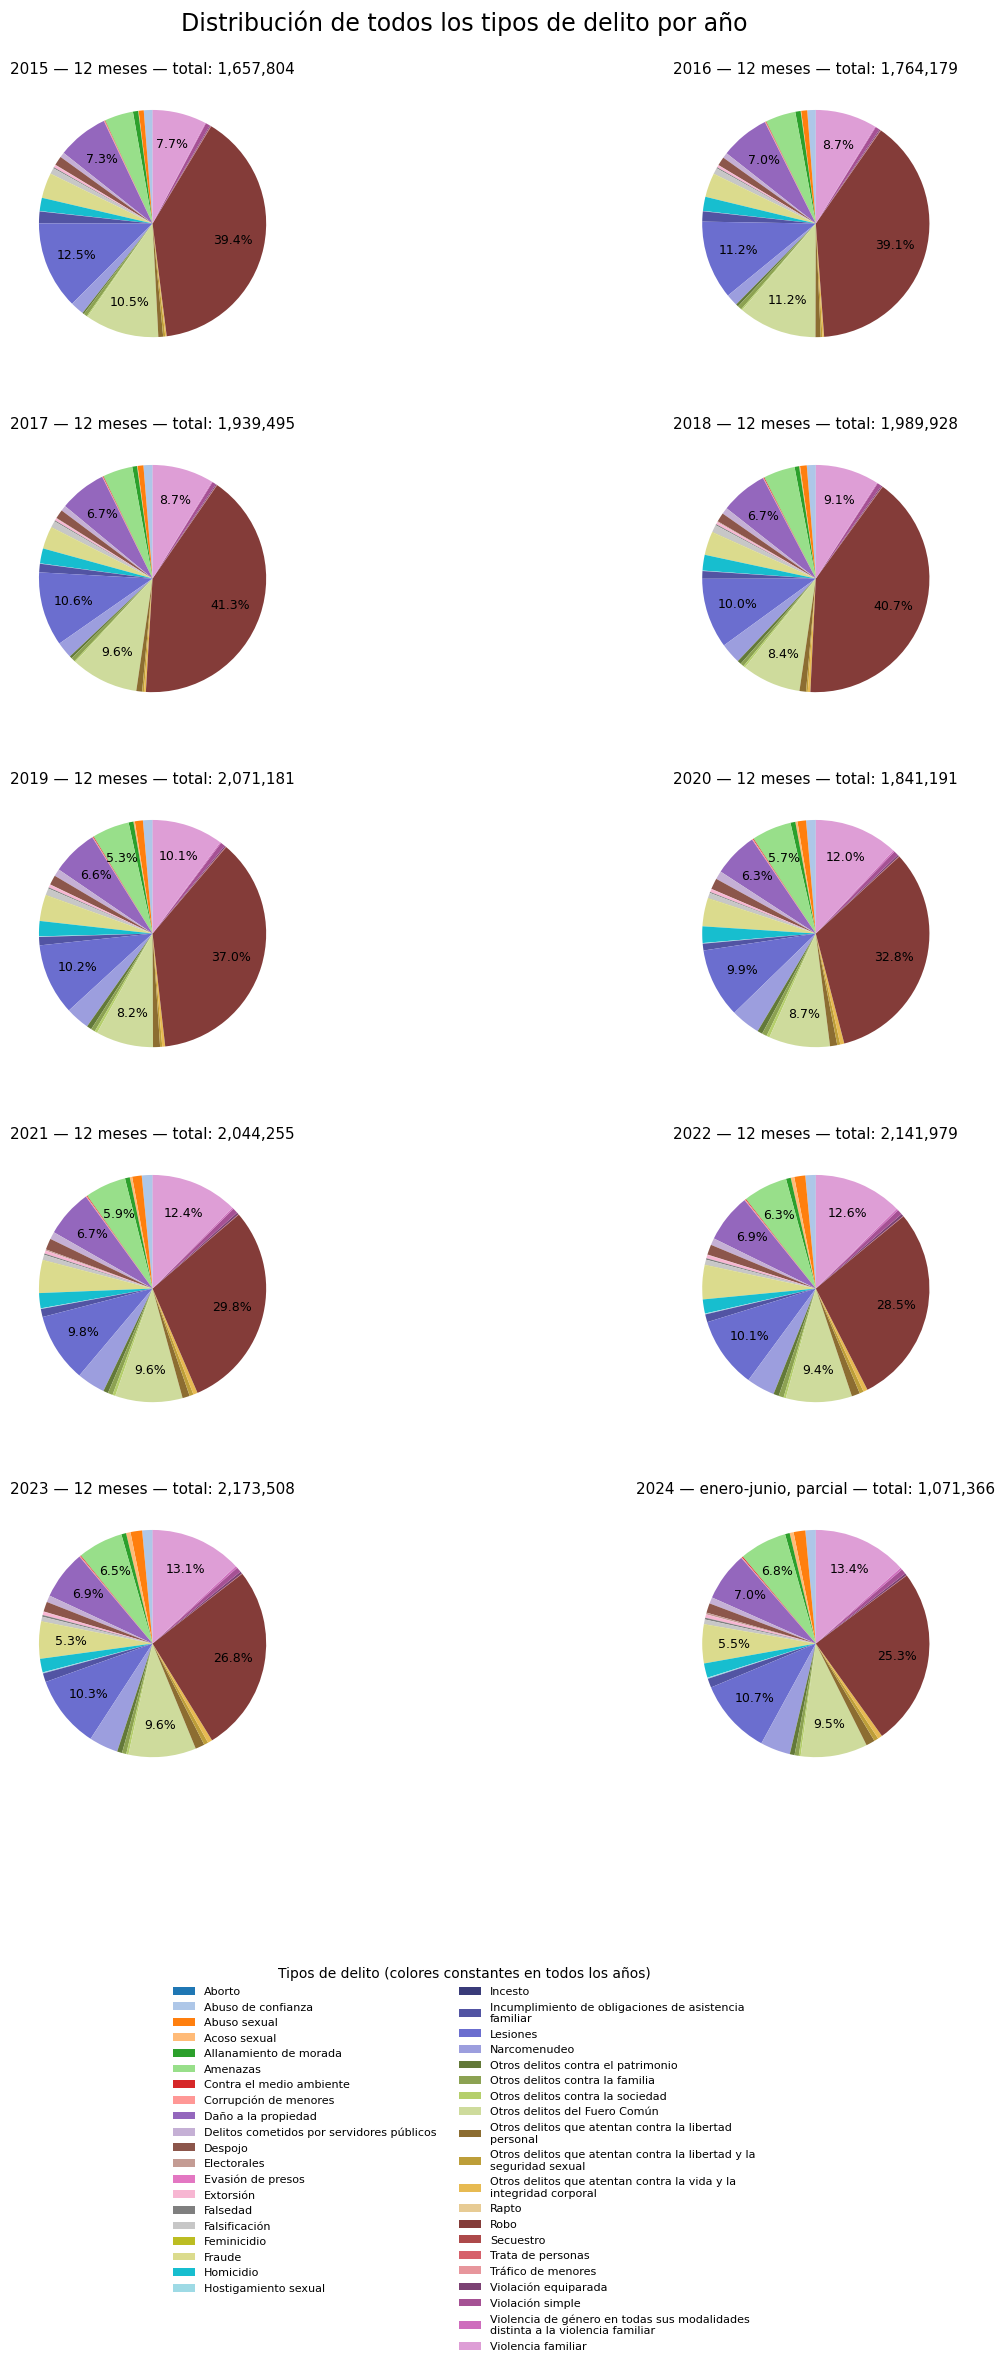

Frecuencias exactas para consultar también los sectores pequeños:


anio,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
tipo_de_delito,,,,,,,,,,
Aborto,544,562,545,605,716,633,703,819,810,396
Abuso de confianza,20013,20796,24424,24741,27454,24719,30497,31032,31089,15444
Abuso sexual,11980,15108,15899,18875,23661,22377,27718,33359,35917,17847
Acoso sexual,1109,1325,1700,2712,4221,5596,7060,10977,13819,6066
Allanamiento de morada,12326,13332,13096,12804,14101,12715,13874,14315,14708,7012
Amenazas,68007,76294,82682,89788,110092,104339,119891,135713,140430,72526
Contra el medio ambiente,1184,1449,1807,2120,2192,1982,2095,2335,2355,1508
Corrupción de menores,1940,1873,1851,1848,2185,2443,2602,2950,2835,1361
Daño a la propiedad,120246,123083,129390,132692,135779,116479,137986,148315,150883,74471


**Interpretación:** cada pastel suma el 100% de los registros del año observado. Sólo se etiquetan porcentajes de al menos 5% para evitar solapamientos; todos los tipos permanecen en el gráfico y en la tabla. Las proporciones de 2024 corresponden únicamente a enero-junio.

In [5]:
# Incluimos los 40 tipos originales; no se ocultan categorías dentro de Otros.
tabla_tipos = df.pivot_table(index='tipo_de_delito', columns='anio',
                            values='frecuencia', aggfunc='sum', fill_value=0).sort_index()
years = tabla_tipos.columns.tolist()
tipos = tabla_tipos.index.tolist()
colores = list(plt.get_cmap('tab20').colors) + list(plt.get_cmap('tab20b').colors)
fig, axes = plt.subplots(int(np.ceil(len(years)/2)), 2, figsize=(16, 24))
for ax, yr in zip(axes.flat, years):
    valores = tabla_tipos[yr]
    ax.pie(valores, colors=colores[:len(tipos)], startangle=90,
           autopct=lambda p: f'{p:.1f}%' if p >= 5 else '',
           pctdistance=0.72, textprops={'fontsize': 9})
    meses_yr = df.loc[df['anio'].eq(yr), 'fecha'].nunique()
    periodo_texto = 'enero-junio, parcial' if meses_yr < 12 else '12 meses'
    ax.set_title(f'{yr} — {periodo_texto} — total: {valores.sum():,}', fontsize=11)
for ax in list(axes.flat)[len(years):]:
    ax.set_visible(False)
from matplotlib.patches import Patch
import textwrap
etiquetas = [textwrap.fill(tipo, width=50) for tipo in tipos]
fig.legend([Patch(facecolor=c) for c in colores[:len(tipos)]], etiquetas,
           loc='lower center', bbox_to_anchor=(0.5, 0.01), ncol=2, fontsize=8,
           title='Tipos de delito (colores constantes en todos los años)', frameon=False)
fig.suptitle('Distribución de todos los tipos de delito por año', fontsize=17, y=0.99)
fig.subplots_adjust(top=0.96, bottom=0.25, hspace=0.25, wspace=0.15)
plt.show()
print('Frecuencias exactas para consultar también los sectores pequeños:')
display(tabla_tipos)
display(Markdown(
    '**Interpretación:** cada pastel suma el 100% de los registros del año observado. '
    'Sólo se etiquetan porcentajes de al menos 5% para evitar solapamientos; '
    'todos los tipos permanecen en el gráfico y en la tabla. '
    'Las proporciones de 2024 corresponden únicamente a enero-junio.'
))


---
#### Calcula la tasa por 100,000 habitantes
##### Tasa por 100,000 habitantes
Mostrar el total de delitos en una entidad no nos sirve de mucho. Es mucho más útil calcular la tasa de incidencia delictiva por cada 100,000 habitantes

$$
tasa = \frac{delitos\space totales}{población} \times 100,000
$$

Esta tasa la podemos anualizar multiplicándola por un factor de 12
$$
tasa\space anualizada = tasa \times 12
$$

Población por entidad federativa según [la encuesta intercensal 2015](https://www.inegi.org.mx/programas/intercensal/2015/)

No tienes que descargar nada. Ya están los datos en la carpeta data

**Aclaración:** el factor 12 sólo anualiza una tasa mensual como proyección. Una suma anual de casos no se vuelve a multiplicar por 12. La población disponible es la de 2015.


**Auditoría del denominador.** El CSV de población tiene cinco cifras asignadas
a otra entidad. Se conserva sin cambios y se corrige la asociación en memoria
con la tabla oficial de [INEGI, Principales resultados de la Encuesta Intercensal
2015, p. 4](https://www.inegi.org.mx/contenidos/productos/prod_serv/contenidos/espanol/bvinegi/productos/nueva_estruc/702825078966.pdf#page=14).
El documento usa Distrito Federal para la actual Ciudad de México.

| Clave | Entidad | Valor en el CSV | Valor de INEGI 2015 |
| ---: | --- | ---: | ---: |
| 05 | Coahuila de Zaragoza | 5,217,908 | 2,954,915 |
| 06 | Colima | 3,556,574 | 711,235 |
| 07 | Chiapas | 8,918,653 | 5,217,908 |
| 08 | Chihuahua | 2,954,915 | 3,556,574 |
| 09 | Ciudad de México | 711,235 | 8,918,653 |

Las otras 27 cifras coinciden con esa tabla. Es una corrección de correspondencia
entre estado y población, no una actualización al año del delito. La población
sigue siendo una estimación de 2015 y no el denominador exacto de otros años.


In [6]:
pobs = pd.read_csv('data/poblacion_entidades_2015.csv', encoding='ISO-8859-1', sep=';')
pobs = pobs[['Cve_Entidad', 'Entidad', 'Poblacion']].rename(columns={
    'Cve_Entidad': 'clave_ent', 'Entidad': 'entidad_poblacion', 'Poblacion': 'poblacion_2015'
})
assert len(pobs) == 32 and pobs['clave_ent'].is_unique
assert pobs['poblacion_2015'].gt(0).all()
assert pobs['poblacion_2015'].mod(1).eq(0).all()
pobs['poblacion_2015'] = pobs['poblacion_2015'].astype('int64')
# Cinco cifras del archivo están desalineadas respecto a la clave estatal.
# Fuente: INEGI, Principales resultados EIC 2015, p. 4 (página 14 del PDF).
# El CSV se conserva intacto; se corrige la asociación sólo en memoria.
pobs['poblacion_2015_archivo'] = pobs['poblacion_2015']
correcciones_inegi = {5: 2_954_915, 6: 711_235, 7: 5_217_908,
                     8: 3_556_574, 9: 8_918_653}
afectadas = pobs['clave_ent'].isin(correcciones_inegi)
pobs.loc[afectadas, 'poblacion_2015'] = pobs.loc[afectadas, 'clave_ent'].map(correcciones_inegi)
assert pobs['poblacion_2015'].sum() == pobs['poblacion_2015_archivo'].sum()
print('Auditoría de las cinco asociaciones corregidas (el archivo original no se modifica):')
display(pobs.loc[afectadas])
display(pobs.head())


Auditoría de las cinco asociaciones corregidas (el archivo original no se modifica):


,clave_ent,entidad_poblacion,poblacion_2015,poblacion_2015_archivo
4,5,Coahuila de Zaragoza,2954915,5217908
5,6,Colima,711235,3556574
6,7,Chiapas,5217908,8918653
7,8,Chihuahua,3556574,2954915
8,9,Ciudad de México,8918653,711235


,clave_ent,entidad_poblacion,poblacion_2015,poblacion_2015_archivo
0,1,Aguascalientes,1312544,1312544
1,2,Baja California,3315766,3315766
2,3,Baja California Sur,712029,712029
3,4,Campeche,899931,899931
4,5,Coahuila de Zaragoza,2954915,5217908


In [7]:
# Una fila de df representa un tipo de delito en un estado y un mes.
df_tasas = df.merge(pobs, on='clave_ent', how='left', validate='many_to_one', indicator=True)
assert df_tasas['_merge'].eq('both').all() and len(df_tasas) == len(df)
df_tasas = df_tasas.drop(columns='_merge')
df_tasas['tasa_mensual_base2015'] = df_tasas['frecuencia'] / df_tasas['poblacion_2015'] * 100_000
df_tasas['tasa_anualizada_base2015'] = df_tasas['tasa_mensual_base2015'] * 12
display(df_tasas[['fecha', 'entidad', 'tipo_de_delito', 'frecuencia', 'poblacion_2015',
                  'tasa_mensual_base2015', 'tasa_anualizada_base2015']].head())
display(Markdown(
    '**Unidades e interpretación:** la tasa mensual es casos del mes / población de 2015 × 100,000. '
    'Multiplicarla por 12 produce una **proyección anual** si ese mes se repitiera; '
    'no es la tasa anual observada. La tasa anual observada usa la suma de los 12 meses '
    'dividida por la población, **sin volver a multiplicar por 12**. '
    'Para otros años, la población fija de 2015 es una referencia: las tasas no son '
    'estimaciones exactas con la población de cada año.'
))


,fecha,entidad,tipo_de_delito,frecuencia,poblacion_2015,tasa_mensual_base2015,tasa_anualizada_base2015
0,2015-01-01,Aguascalientes,Aborto,0,1312544,0.000000,0.000000
1,2015-01-01,Aguascalientes,Abuso de confianza,41,1312544,3.123705,37.484458
2,2015-01-01,Aguascalientes,Abuso sexual,6,1312544,0.457128,5.485530
3,2015-01-01,Aguascalientes,Acoso sexual,0,1312544,0.000000,0.000000
4,2015-01-01,Aguascalientes,Allanamiento de morada,13,1312544,0.990443,11.885316


**Unidades e interpretación:** la tasa mensual es casos del mes / población de 2015 × 100,000. Multiplicarla por 12 produce una **proyección anual** si ese mes se repitiera; no es la tasa anual observada. La tasa anual observada usa la suma de los 12 meses dividida por la población, **sin volver a multiplicar por 12**. Para otros años, la población fija de 2015 es una referencia: las tasas no son estimaciones exactas con la población de cada año.

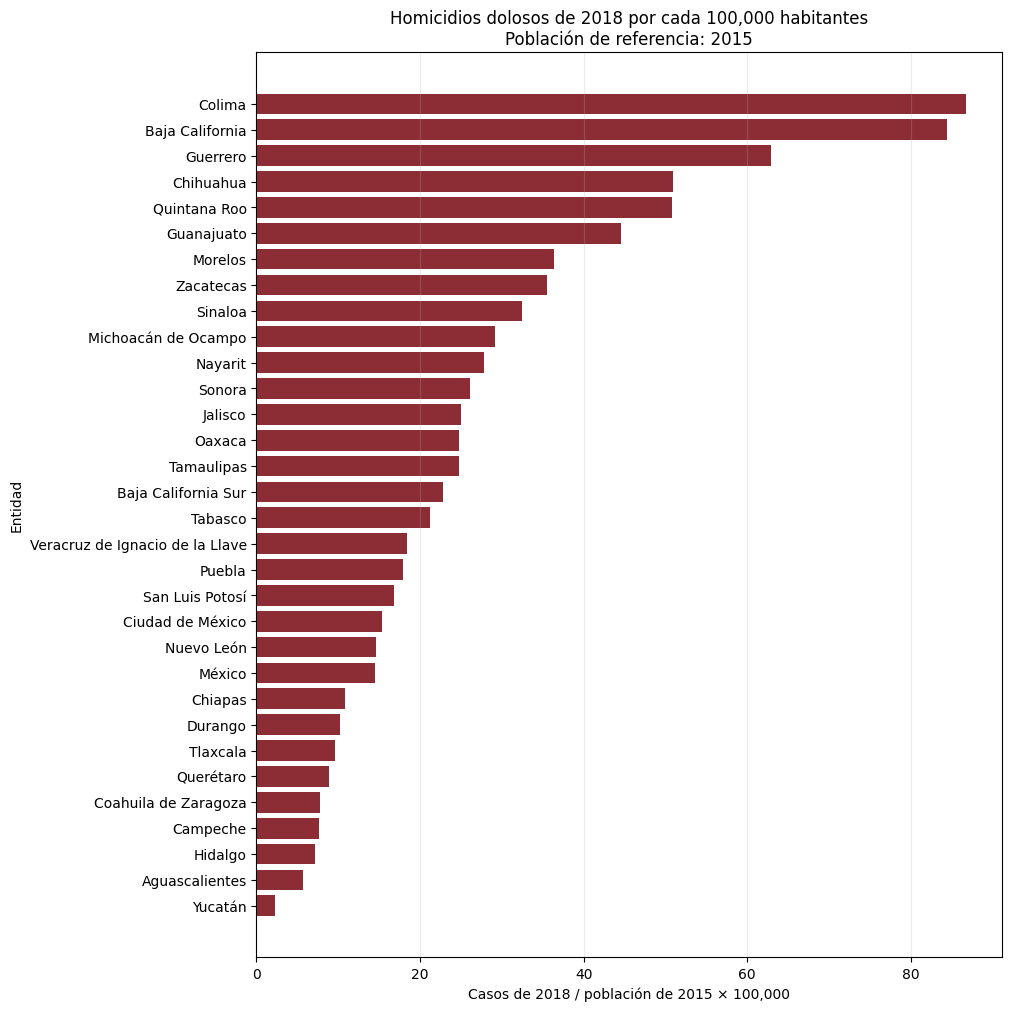

,entidad,frecuencia,poblacion_2015,tasa_periodo_base2015
101,Colima,617,711235,86.750511
97,Baja California,2798,3315766,84.384724
107,Guerrero,2222,3533251,62.888258
103,Chihuahua,1809,3556574,50.863556
118,Quintana Roo,763,1501562,50.813753


**Respuesta e interpretación:** Colima tiene 617 homicidios dolosos en 2018 y 711,235 habitantes como base de referencia: 617 / 711,235 × 100,000 = **86.75 por 100,000**. La mayor tasa con esta base corresponde a **Colima** (86.75). Normalizar por población cambia la comparación de los números absolutos. Se usan 12 meses reales; estas tasas conservan la limitación de utilizar población de 2015.

In [8]:
# Comparación anual con los mismos homicidios dolosos solicitados en el ejercicio 1.
homicidios_anual = dolosos.groupby(['anio', 'clave_ent', 'entidad'], as_index=False)['frecuencia'].sum()
homicidios_anual = homicidios_anual.merge(pobs, on='clave_ent', how='left', validate='many_to_one')
homicidios_anual['meses_observados'] = homicidios_anual['anio'].map(df.groupby('anio')['fecha'].nunique())
homicidios_anual['tasa_periodo_base2015'] = (
    homicidios_anual['frecuencia'] / homicidios_anual['poblacion_2015'] * 100_000
)
homicidios_2018 = homicidios_anual.loc[homicidios_anual['anio'].eq(2018)].sort_values(
    'tasa_periodo_base2015', ascending=False
).copy()
assert len(homicidios_2018) == 32 and homicidios_2018['meses_observados'].eq(12).all()
fig, ax = plt.subplots(figsize=(10, 10), layout='constrained')
ax.barh(homicidios_2018['entidad'], homicidios_2018['tasa_periodo_base2015'], color='#8c2d36')
ax.invert_yaxis()
ax.set(title='Homicidios dolosos de 2018 por cada 100,000 habitantes\nPoblación de referencia: 2015',
       xlabel='Casos de 2018 / población de 2015 × 100,000', ylabel='Entidad')
ax.grid(axis='x', alpha=0.25)
plt.show()
display(homicidios_2018[['entidad', 'frecuencia', 'poblacion_2015', 'tasa_periodo_base2015']].head(5))
ejemplo = homicidios_2018.loc[homicidios_2018['entidad'].eq('Colima')].iloc[0]
lider = homicidios_2018.iloc[0]
display(Markdown(
    f'**Respuesta e interpretación:** Colima tiene {int(ejemplo.frecuencia):,} homicidios dolosos '
    f'en 2018 y {int(ejemplo.poblacion_2015):,} habitantes como base de referencia: '
    f'{int(ejemplo.frecuencia):,} / {int(ejemplo.poblacion_2015):,} × 100,000 = '
    f'**{ejemplo.tasa_periodo_base2015:.2f} por 100,000**. '
    f'La mayor tasa con esta base corresponde a **{lider.entidad}** '
    f'({lider.tasa_periodo_base2015:.2f}). '
    'Normalizar por población cambia la comparación de los números absolutos. '
    'Se usan 12 meses reales; estas tasas conservan la limitación de utilizar población de 2015.'
))
